In [11]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from sklearn.linear_model import Lasso, Ridge, LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
import warnings
from sklearn.exceptions import ConvergenceWarning   # For part D4 so it will run
warnings.simplefilter("ignore", ConvergenceWarning)
import seaborn as sns

# ==============================================================================

import plot_params
from config import SEED, FIGURES_PATH, RESULTS_PATH, DATA_PATH
from Data.data import load_mnist, train_val_split, one_hot, to_column
from Machine.network import NeuralNetwork
from Machine.optimizers import train
from Machine.metrics import mse_score, accuracy, confusion_matrix, precision_recall_f1
import utils as u       # Reused functions from Project 1

RERUN = False   # load saved results when they exist

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part b)** Neural network

</div>

In [12]:
# ----- B1: Data, OLS benchmark ------------------------------------------------
x_train, x_test, y_train, y_test = u.create_dataset()   # Project 1's data
X_tr, X_te = to_column(x_train), to_column(x_test)      # the network wants shape (n, 1)
Y_tr, Y_te = to_column(y_train), to_column(y_test)

# OLS benchmark: best polynomial degree by test MSE
max_deg = 20
ols_mse = np.zeros(max_deg)
for d in range(1, max_deg + 1):
    Xd_tr, Xd_te = u.create_feature_matrix(x_train, x_test, degree=d)
    theta = u.closed_form(Xd_tr, y_train)
    ols_mse[d - 1] = mse_score(y_test, Xd_te @ theta)
best_deg = int(np.argmin(ols_mse)) + 1
print(f"OLS: best degree {best_deg}, test MSE {ols_mse[best_deg - 1]:.4f}")

# validation set from the training data, for choosing learning rates
X_fit, X_val, Y_fit, Y_val = train_val_split(X_tr, Y_tr, val_size=0.25, seed=SEED, stratify=False)

OLS: best degree 10, test MSE 0.0087


best on validation: SGD + RMSprop, gamma = 1.0e-01, val MSE 0.0145


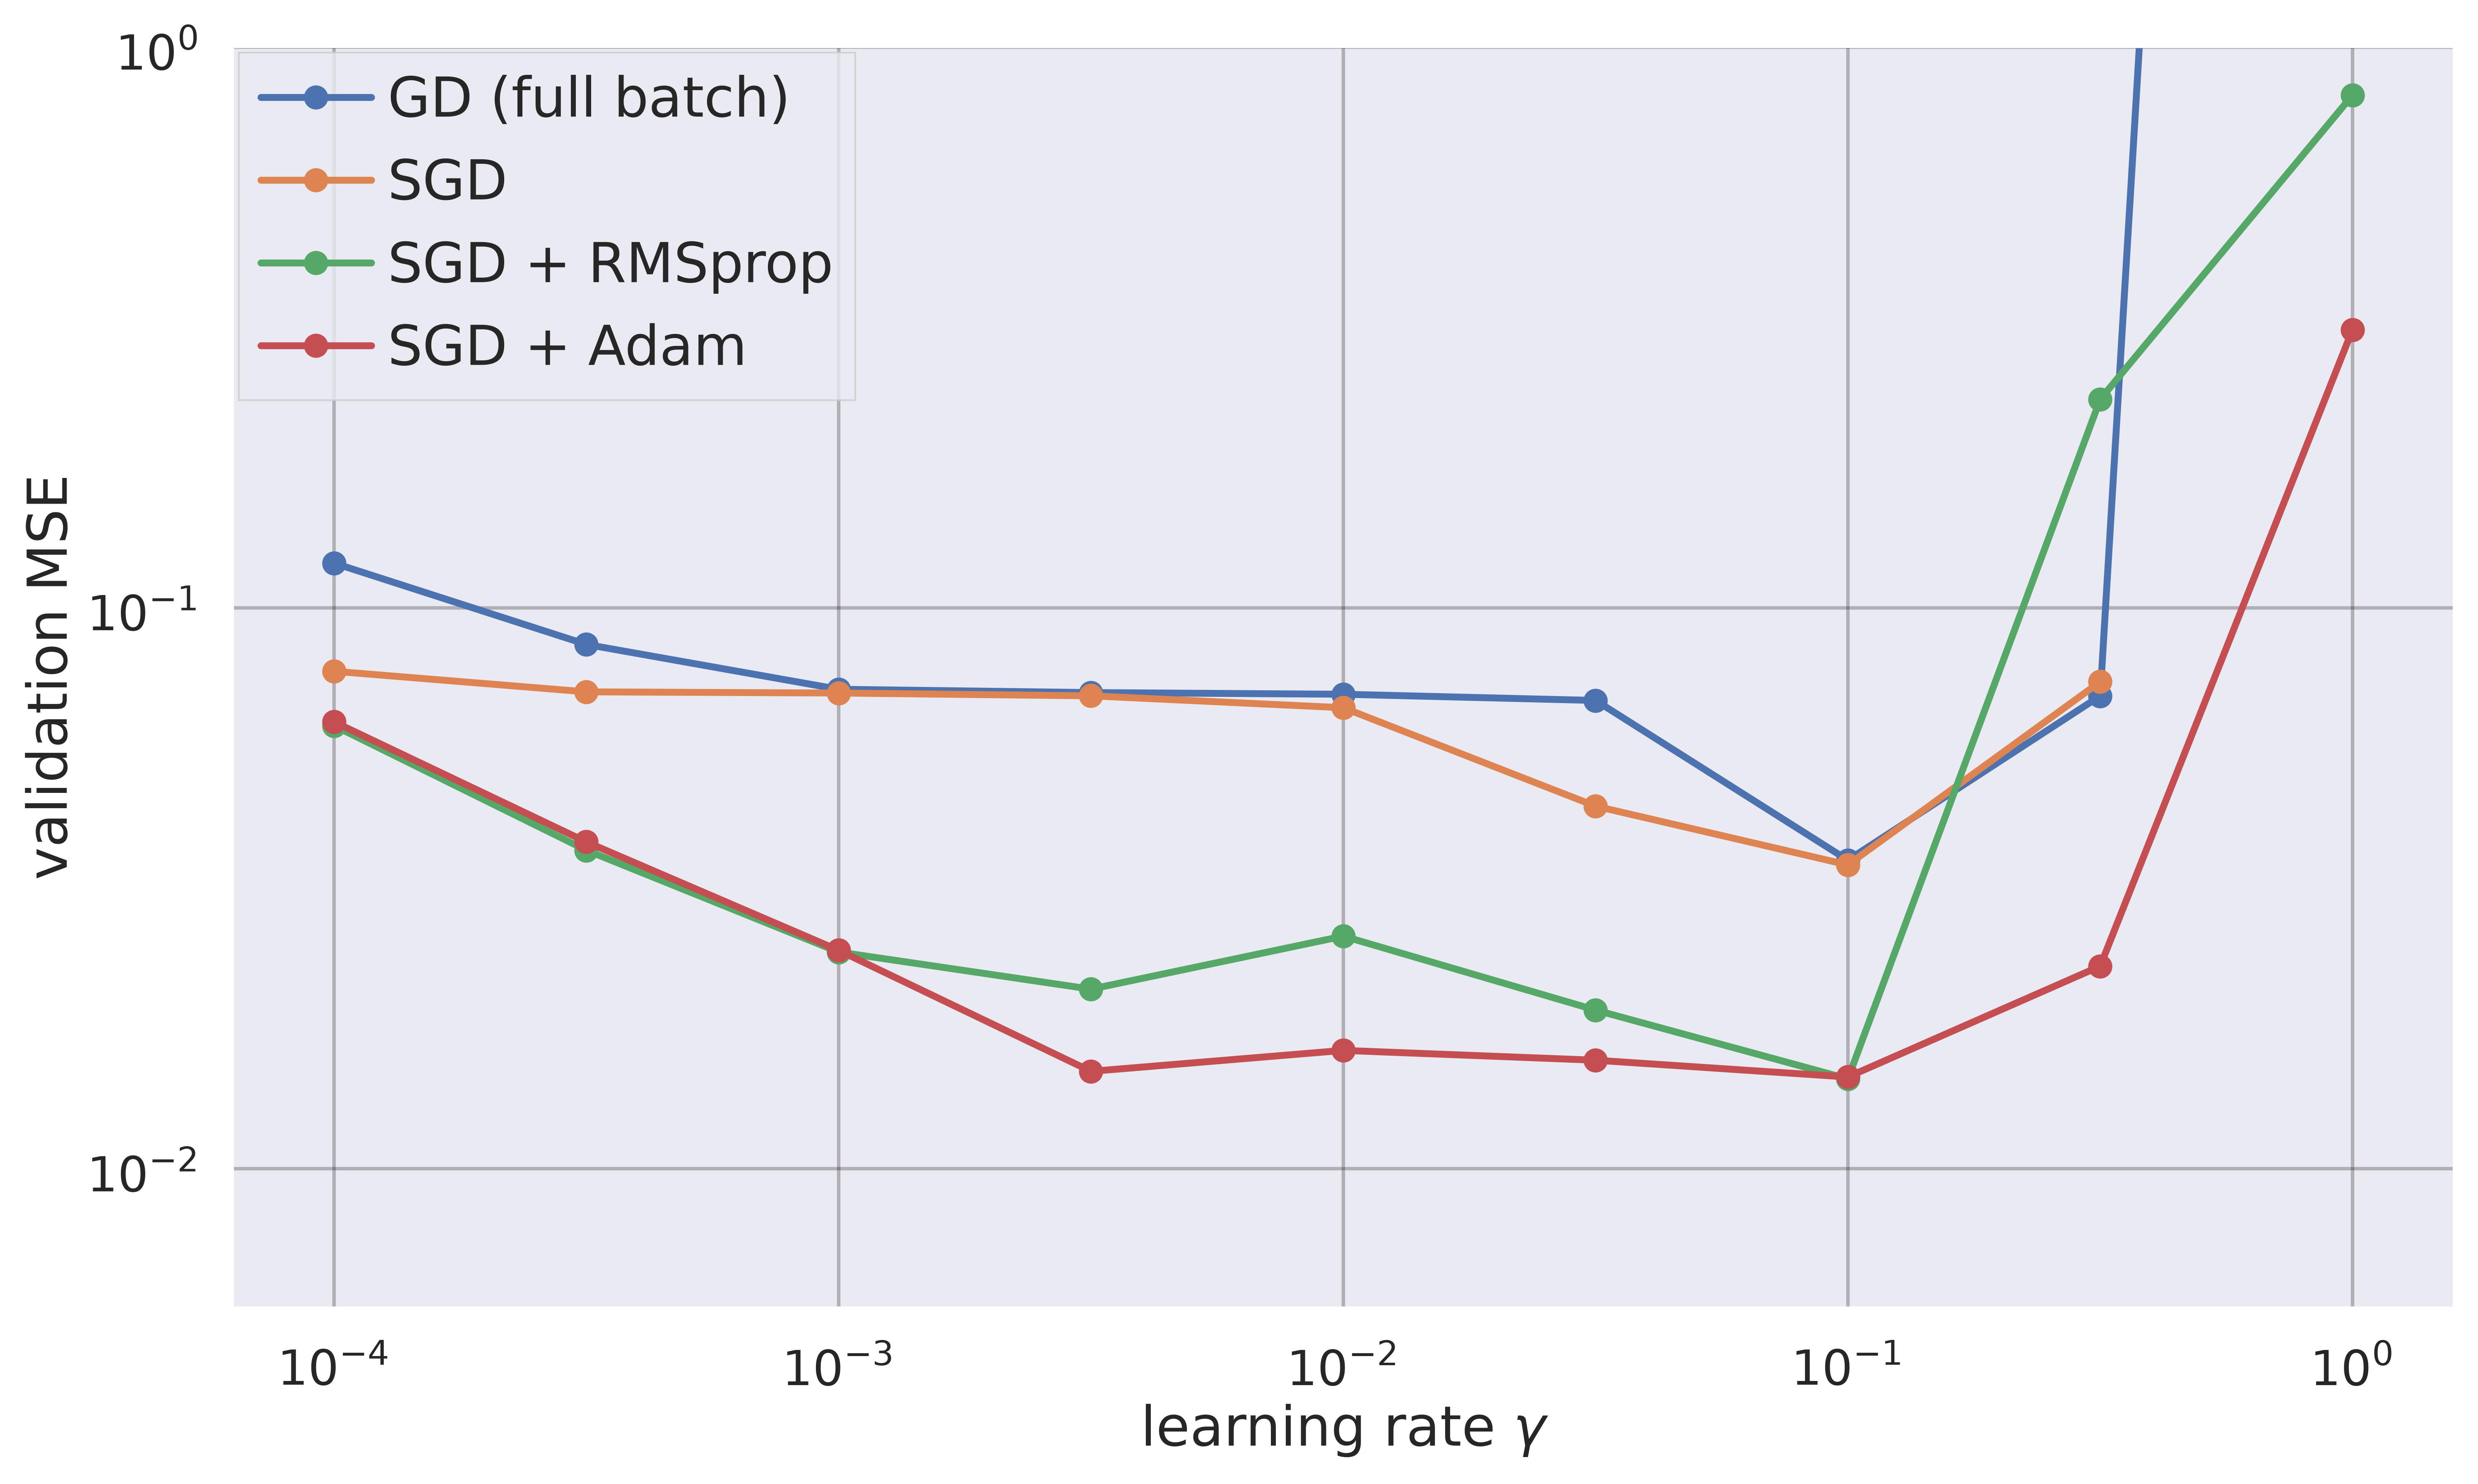

In [13]:
# ----- B2: Learning rate sweep ------------------------------------------------
VARIANTS = {                        # name: (optimizer, batch size)
    "GD (full batch)": ("plain", None),
    "SGD": ("plain", 10),
    "SGD + RMSprop": ("rmsprop", 10),
    "SGD + Adam": ("adam", 10)
}
gammas = np.geomspace(1e-4, 1.0, 9)
EPOCHS = 1000
sweep_path = RESULTS_PATH / "b_lr_sweep.npz"

if RERUN or not sweep_path.exists():
    val_mse = np.full((len(VARIANTS), len(gammas)), np.nan)
    for i, (method, batch_size) in enumerate(VARIANTS.values()):
        for j, gamma in enumerate(gammas):
            net = NeuralNetwork([1, 50, 1], ["sigmoid", "identity"], "mse", seed=SEED)
            with np.errstate(all="ignore"):
                train(net, X_fit, Y_fit, method=method, gamma=gamma, epochs=EPOCHS,
                      batch_size=batch_size, seed=SEED)
                val_mse[i, j] = mse_score(Y_val, net.predict(X_val))
    np.savez(sweep_path, val_mse=val_mse, gammas=gammas)
else:
    saved = np.load(sweep_path)
    val_mse, gammas = saved["val_mse"], saved["gammas"]
    
names = list(VARIANTS)
best_i, best_j = np.unravel_index(np.nanargmin(val_mse), val_mse.shape)
print(f"best on validation: {names[best_i]}, "
      f"gamma = {gammas[best_j]:.1e}, val MSE {val_mse[best_i, best_j]:.4f}")

fig, ax = plt.subplots(figsize=(10, 6))
for i, name in enumerate(names):
    ax.loglog(gammas, val_mse[i], "o-", label=name)
ax.set_xlabel(r"learning rate $\gamma$")
ax.set_ylabel("validation MSE")
ax.set_ylim(top=1.0)
ax.legend()
plt.savefig(FIGURES_PATH / "B-learning_rate_sweep.pdf")
plt.show()

In [14]:
# ----- B3: Architectures ------------------------------------------------------
ARCHS = {
    "1 x 50":   [1, 50, 1],
    "1 x 500":  [1, 500, 1],
    "2 x 50":   [1, 50, 50, 1],
    "2 x 100":  [1, 100, 100, 1]
}
method, batch_size = list(VARIANTS.values())[best_i]   # best optimizer from B2

# dense grid on the standardsized coordinates, to draw smooth curves
x_raw, y_raw = u.create_dataset(split=False, rescale=False)
xg = np.linspace(-1, 1, 400)
xg_std = (xg - x_raw.mean()) / x_raw.std()

arch_path = RESULTS_PATH / "b_architectures.npz"
if RERUN or not arch_path.exists():
    best_gammas, train_mse, test_mse, curves = [], [], [], []
    for sizes in ARCHS.values():
        acts = ["sigmoid"] * (len(sizes) - 2) + ["identity"]
        
        # 1: choose gamma for this architecture on the validation set
        scores = []
        for g in gammas:
            net = NeuralNetwork(sizes, acts, "mse", seed=SEED)
            with np.errstate(all="ignore"):
                train(net, X_fit, Y_fit, method=method, gamma=g, epochs=EPOCHS,
                      batch_size=batch_size, seed=SEED)
            scores.append(mse_score(Y_val, net.predict(X_val)))
        g_best = gammas[np.nanargmin(scores)]
        
        # 2: retain on full training set with that gamma, then look at test once
        net = NeuralNetwork(sizes, acts, "mse", seed=SEED)
        train(net, X_tr, Y_tr, method=method, gamma=g_best, epochs=EPOCHS,
              batch_size=batch_size, seed=SEED)
        best_gammas.append(g_best)
        train_mse.append(mse_score(Y_tr, net.predict(X_tr)))
        test_mse.append(mse_score(Y_te, net.predict(X_te)))
        curves.append(net.predict(to_column(xg_std)).ravel())
    best_gammas, train_mse, test_mse, curves = map(np.array, (best_gammas, train_mse, test_mse, curves))
    np.savez(arch_path, best_gammas=best_gammas, train_mse=train_mse, test_mse=test_mse, curves=curves)
else:
    saved = np.load(arch_path)
    best_gammas, train_mse, test_mse, curves = (saved[k] for k in ("best_gammas", "train_mse", "test_mse", "curves"))

# OLS fit with the best degree, on the same grid
Xd_tr = u.create_feature_matrix(x_train, degree=best_deg)
theta = u.closed_form(Xd_tr, y_train)
ols_curve = u.create_feature_matrix(xg_std, degree=best_deg) @ theta
ols_train = mse_score(y_train, Xd_tr @ theta)

model             gamma  train MSE  test MSE
OLS deg 10                  0.0111    0.0087
NN 1 x 50       1.0e-01     0.0148    0.0154
NN 1 x 500      1.0e-01     0.0125    0.0153
NN 2 x 50       1.0e-03     0.0112    0.0112
NN 2 x 100      1.0e-02     0.0100    0.0187


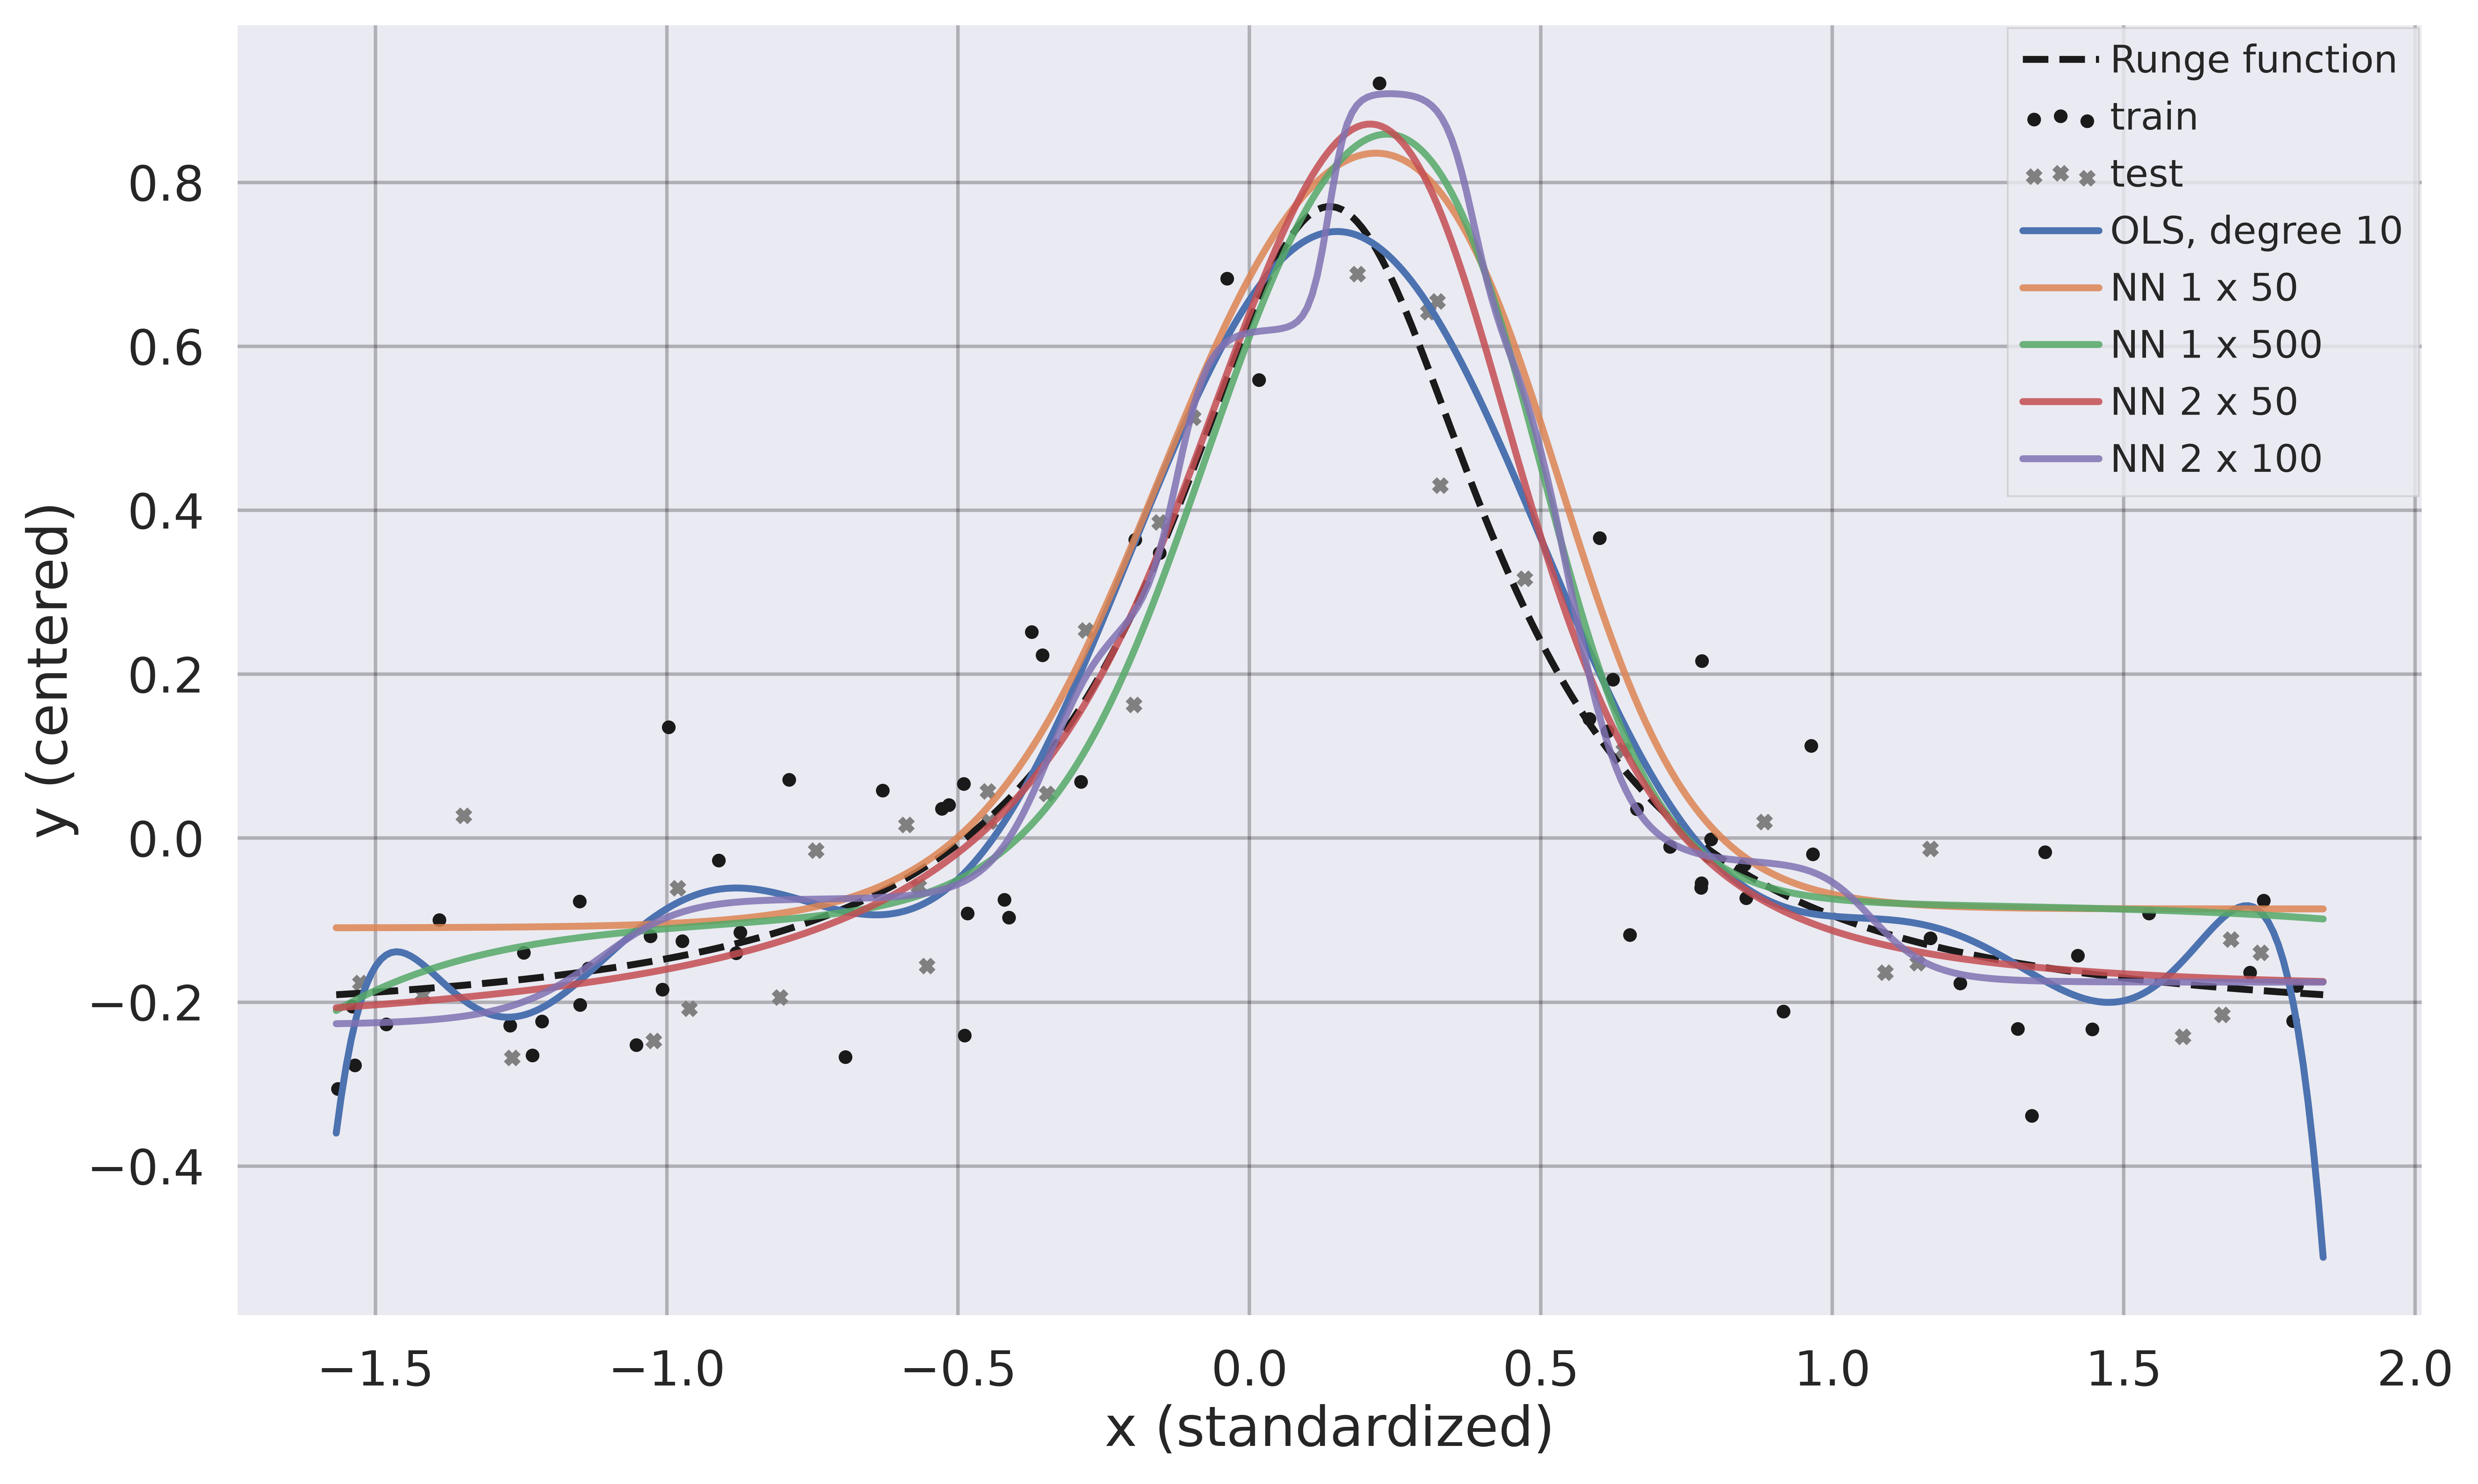

In [15]:
# ----- B4: Results ------------------------------------------------------------
print(f"{'model':<14}{'gamma':>9}{'train MSE':>11}{'test MSE':>10}")
print(f"{'OLS deg ' + str(best_deg):<14}{'':>9}{ols_train:>11.4f}{ols_mse[best_deg - 1]:>10.4f}")
for name, g, tr, te in zip(ARCHS, best_gammas, train_mse, test_mse):
    print(f"{'NN ' + name:<14}{g:>9.1e}{tr:>11.4f}{te:>10.4f}")
    
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(xg_std, 1 / (1 + 25 * xg**2) - y_raw.mean(), "k--", label="Runge function")
ax.scatter(x_train, y_train, s=12, color="k", label="train")
ax.scatter(x_test, y_test, s=12, color="gray", label="test", marker="x")
ax.plot(xg_std, ols_curve, label=f"OLS, degree {best_deg}")
for name, curve in zip(ARCHS, curves):
    ax.plot(xg_std, curve, label=f"NN {name}", alpha=0.85)
ax.set_xlabel("x (standardized)")
ax.set_ylabel("y (centered)")
ax.legend(loc="upper right", fontsize=11)
plt.savefig(FIGURES_PATH / "B-NN_vs_OLS_fits.pdf")
plt.show()

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part c)** Activation functions and depths

</div>

In [16]:
# ----- C1: Settings and sweep -------------------------------------------------
ACTS   = ["sigmoid", "relu", "leaky_relu"]
DEPTHS = [1, 2, 3, 4]           # number of hidden layers
WIDTHS = [10, 25, 50, 100]      # nodes per hidden layer
GAMMAS = np.geomspace(1e-3, 1.0, 4) # 1e-3, 1e-2, 1e-1. 1
SEEDS  = [0, 1, 2]              # average over inputs, since the data is tiny
EPOCHS = 500

def run_one(act, depth, width, gamma, seed):
    sizes = [1] + [width] * depth + [1]
    acts  = [act] * depth + ["identity"]
    net = NeuralNetwork(sizes, acts, "mse", seed=seed)
    hist = train(net, X_fit, Y_fit, method="rmsprop", gamma=gamma,
                 epochs=EPOCHS, batch_size=10,
                 X_val=X_val, Y_val=Y_val)
    return hist["train_cost"][-1], hist["val_cost"][-1]

path = RESULTS_PATH / "c_depth_width.npz"
if RERUN or not path.exists():
    shape = (len(ACTS), len(DEPTHS), len(WIDTHS), len(GAMMAS), len(SEEDS))
    tr = np.full(shape, np.inf)
    va = np.full(shape, np.inf)
    for a, act in enumerate(ACTS):
        for d, depth in enumerate(DEPTHS):
            for w, width in enumerate(WIDTHS):
                for g, gamma in enumerate(GAMMAS):
                    for s, seed in enumerate(SEEDS):
                        with np.errstate(all="ignore"):
                            t, v = run_one(act, depth, width, gamma, seed)
                        if np.isfinite(t) and np.isfinite(v):
                            tr[a, d, w, g, s], va[a, d, w, g, s] = t, v
    np.savez(path, tr=tr, va=va)
else:
    data = np.load(path)
    tr, va = data["tr"], data["va"]

sigmoid    best: depth 3, 50, gamma 1e-03, val MSE 0.0133
relu       best: depth 4, 25, gamma 1e-03, val MSE 0.0148
leaky_relu best: depth 3, 10, gamma 1e-03, val MSE 0.0141


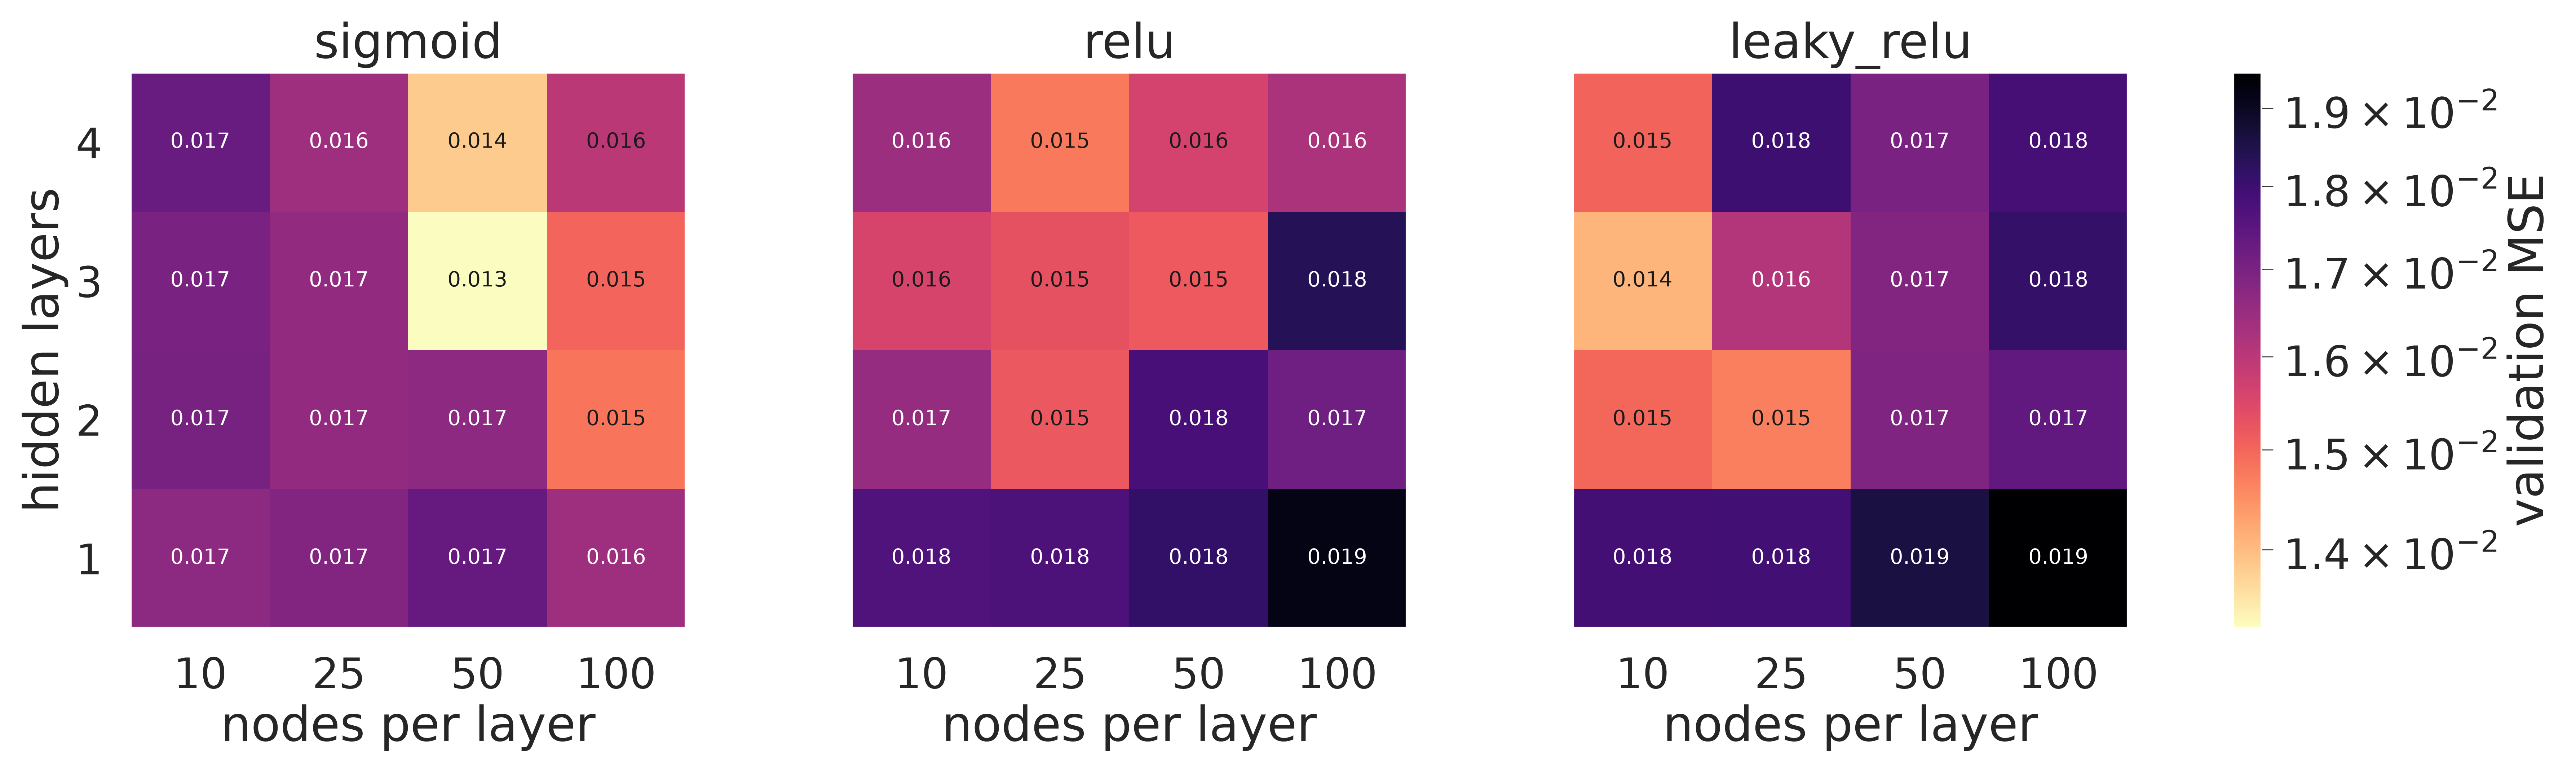

In [17]:
# ----- C2: Best gamma per cell ------------------------------------------------
va_m = va.mean(axis=-1)          # averaging over seeds
tr_m = tr.mean(axis=-1)
best_g = va_m.argmin(axis=-1)   # best gamma index per cell
take = lambda M: np.take_along_axis(M, best_g[..., None], axis=-1)[..., 0]
va_best, tr_best = take(va_m), take(tr_m)

show = np.where(np.isfinite(va_best), va_best, np.nan)
vmin, vmax = np.nanmin(show), min(np.nanmax(show), 1.0)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, act, M in zip(axes, ACTS, show):
    im = ax.imshow(M, origin="lower", cmap="magma_r", norm=LogNorm(vmin, vmax))
    ax.grid(False)
    ax.set_xticks(range(len(WIDTHS)), WIDTHS)
    ax.set_yticks(range(len(DEPTHS)), DEPTHS)
    ax.set_title(act)
    ax.set_xlabel("nodes per layer")
    for (r, c), v in np.ndenumerate(M):
        if np.isfinite(v):
            ax.text(c, r, f"{v:.3f}", ha="center", va="center", fontsize=7,
                    color="w" if im.norm(v) > 0.5 else "k")
axes[0].set_ylabel("hidden layers")
fig.colorbar(im, ax=axes, label="validation MSE")
fig.savefig(FIGURES_PATH / "C-activation_depth_width.pdf")

# winners
for a, act in enumerate(ACTS):
    d, w = np.unravel_index(np.where(np.isfinite(va_best[a]), va_best[a], np.inf).argmin(),
                            va_best[a].shape)
    print(f"{act:10s} best: depth {DEPTHS[d]}, {WIDTHS[w]}, "
          f"gamma {GAMMAS[best_g[a, d, w]]:.0e}, val MSE {va_best[a, d, w]:.4f}")

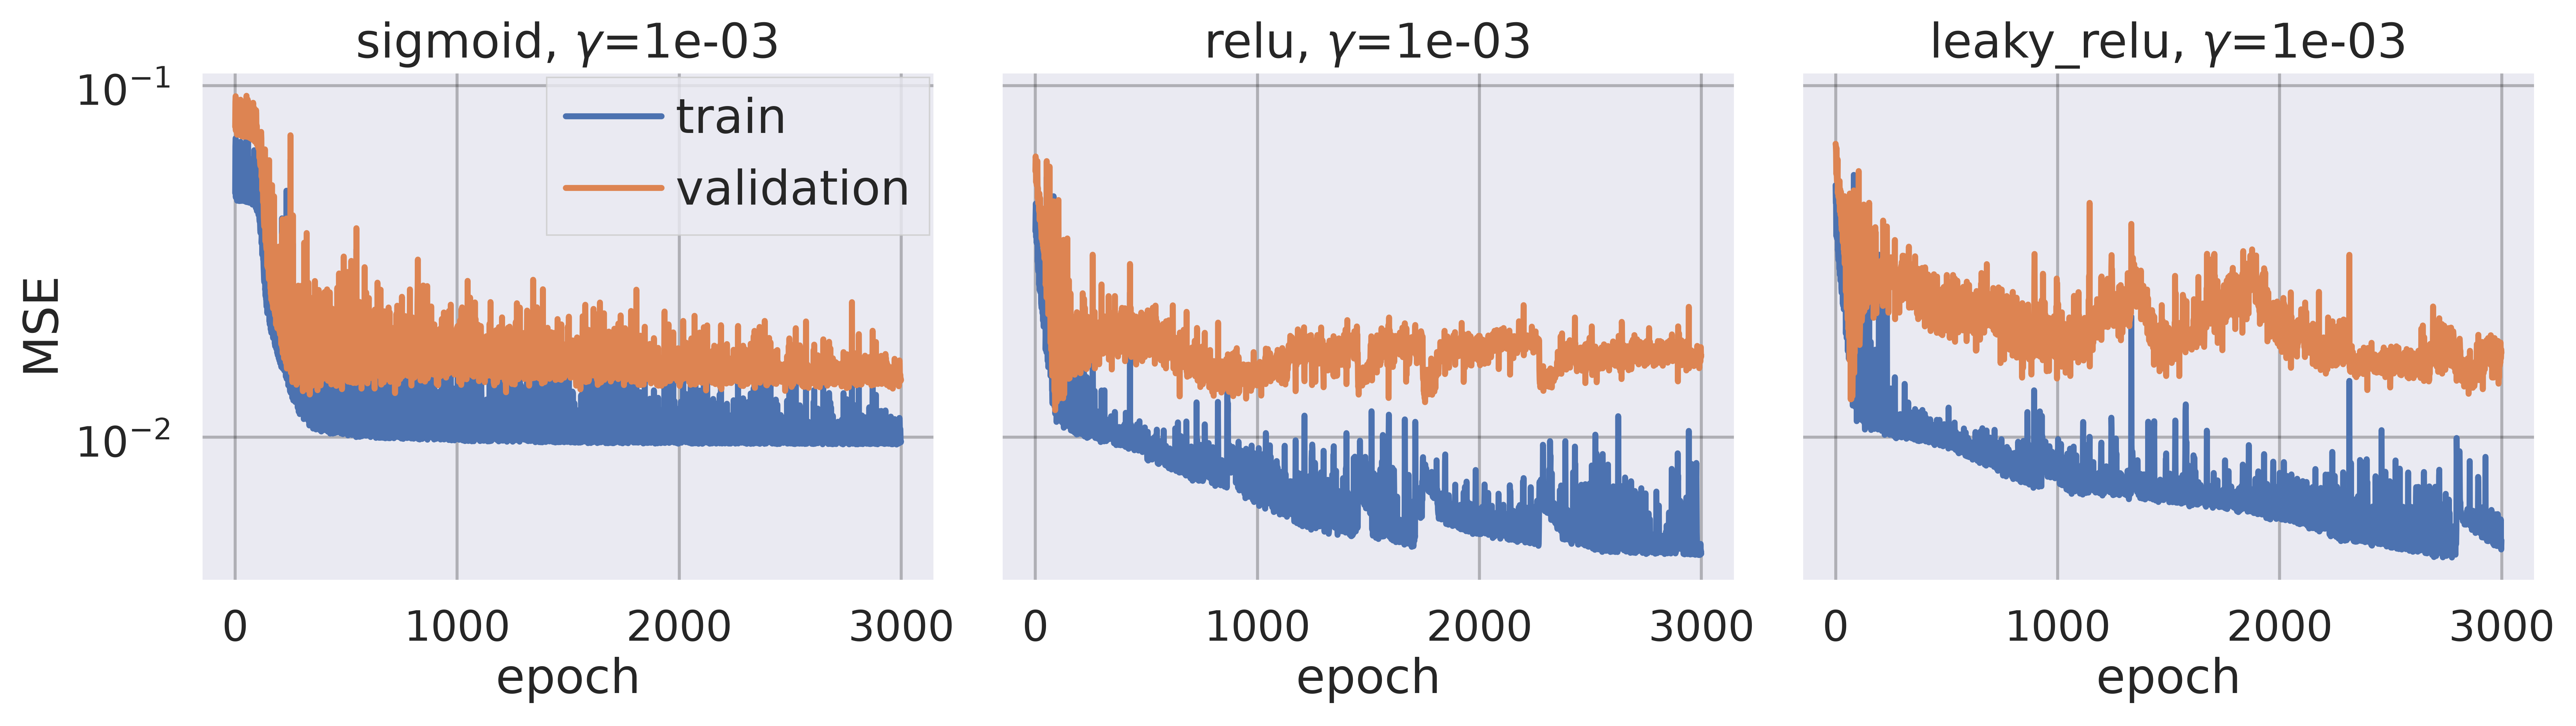

In [18]:
# ----- C3: Overfitting --------------------------------------------------------
d_i, w_i = len(DEPTHS) - 1, len(WIDTHS) - 1     # biggest network
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for i, (ax, act) in enumerate(zip(axes, ACTS)):
    gamma = GAMMAS[best_g[i, d_i, w_i]]
    net = NeuralNetwork([1] + [WIDTHS[w_i]] * DEPTHS[d_i] + [1],
                        [act] * DEPTHS[d_i] + ["identity"], "mse", seed=SEED)
    with np.errstate(all="ignore"):
        h = train(net, X_fit, Y_fit, method="rmsprop", gamma=gamma, epochs=3000,
                  batch_size=10, X_val=X_val, Y_val=Y_val, seed=SEED)
    ax.semilogy(h["train_cost"], label="train")
    ax.semilogy(h["val_cost"], label="validation")
    ax.set_title(f"{act}, $\\gamma$={gamma:.0e}")
    ax.set_xlabel("epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()
fig.savefig(FIGURES_PATH / "C-train_val_curves.pdf")

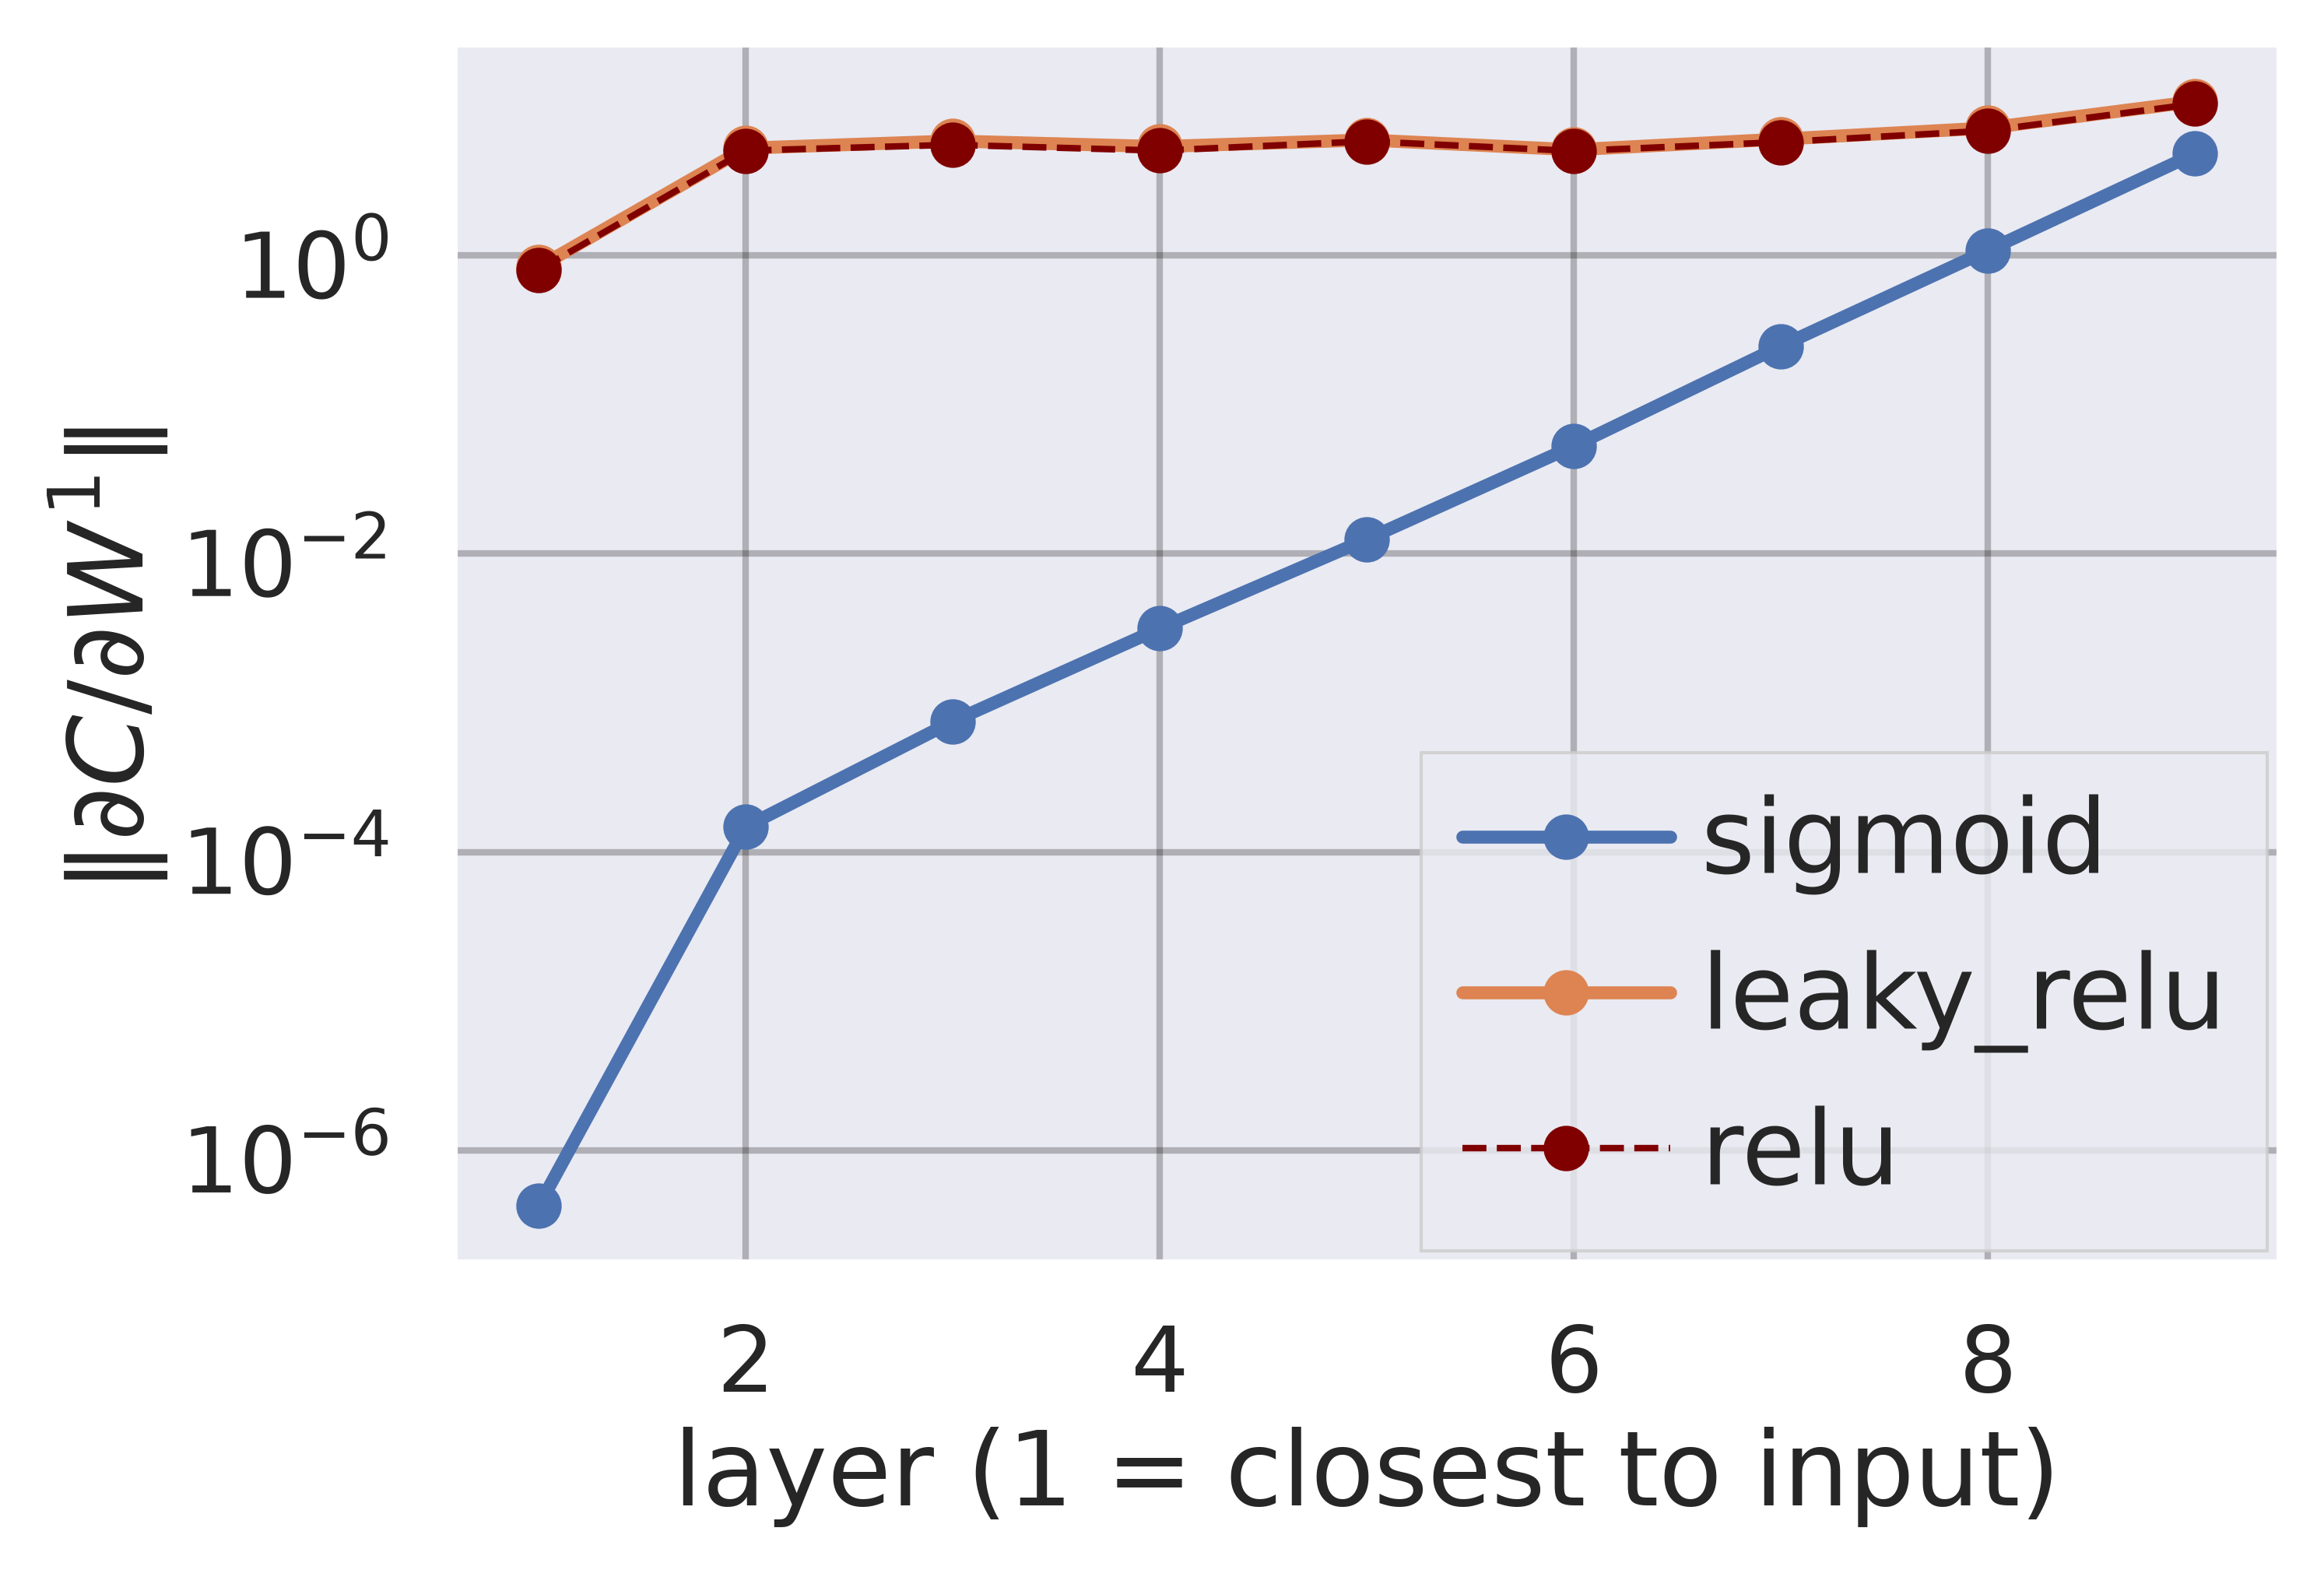

In [19]:
# ----- C4: Vanishing gradients ------------------------------------------------
def layer_grad_norms(act, depth=8, width=50, seed=SEED):
    net = NeuralNetwork([1] + [width] * depth + [1],
                        [act] * depth + ["identity"], "mse", seed=seed)
    grads = net.compute_gradient(X_fit, Y_fit)  # at initialization, no training
    return [np.linalg.norm(gW) for gW, _ in grads]

fig, ax = plt.subplots(figsize=(5, 3.4))
for act in ("sigmoid", "leaky_relu"):
    ax.semilogy(range(1, 10), layer_grad_norms(act), "o-", label=act)
ax.semilogy(range(1, 10), layer_grad_norms("relu"), "o--", label="relu", color="maroon", lw=1)
ax.set_xlabel("layer (1 = closest to input)")
ax.set_ylabel(r"$\|\partial C/\partial W^1\|$")
ax.legend()
fig.savefig(FIGURES_PATH / "C-gradient_norms.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part d)** Different norms

</div>

In [20]:
# ----- D1: Best architecture from C -------------------------------------------
score = np.where(np.isfinite(va_best), va_best, np.inf)
a_i, d_i, w_i = np.unravel_index(score.argmin(), score.shape)
ACT, DEPTH, WIDTH = ACTS[a_i], DEPTHS[d_i], WIDTHS[w_i]
print(f"{ACT} [d:{DEPTH}, w:{WIDTH}], gamma from part C:",
      GAMMAS[best_g[a_i, d_i, w_i]])

sigmoid [d:3, w:50], gamma from part C: 0.001


In [21]:
# ----- D2: Sweep --------------------------------------------------------------
LAMBDAS  = np.concatenate([[0], np.logspace(-6, -3, 7)])
GAMMAS_D = np.geomspace(1e-4, 1e-1, 7)
SEEDS_D  = [0, 1, 2]
EPOCHS_D = 500

def run_pen(norm, lam, gamma, seed):
    l1, l2 = (lam, 0.0) if norm == "l1" else (0.0, lam)
    net = NeuralNetwork([1] + [WIDTH] * DEPTH + [1],
                        [ACT] * DEPTH + ["identity"],
                        "mse", lmbd1=l1, lmbd2=l2, seed=seed)
    train(net, X_fit, Y_fit, method="rmsprop", gamma=gamma, epochs=EPOCHS_D,
          batch_size=10, seed=seed)
    # score predictions directly; MSE without penalty
    return mse_score(Y_val, net.predict(X_val))

path = RESULTS_PATH / "d_lambda_gamma.npz"
if RERUN or not path.exists():
    res = {}
    for norm in ["l2", "l1"]:
        R = np.full((len(LAMBDAS), len(GAMMAS_D), len(SEEDS_D)), np.inf)
        for l, lam in enumerate(LAMBDAS):
            for g, gamma in enumerate(GAMMAS_D):
                for s, seed in enumerate(SEEDS_D):
                    with np.errstate(all="ignore"):
                        v = run_pen(norm, lam, gamma, seed)
                    if np.isfinite(v):
                        R[l, g, s] = v
        res[norm] = R
    np.savez(path, **res)
else:
    d = np.load(path)
    res = {"l2": d["l2"], "l1": d["l1"]}

l2: best lambda 0e+00, gamma 1e-03, val MSE 0.0144
l1: best lambda 0e+00, gamma 1e-03, val MSE 0.0144


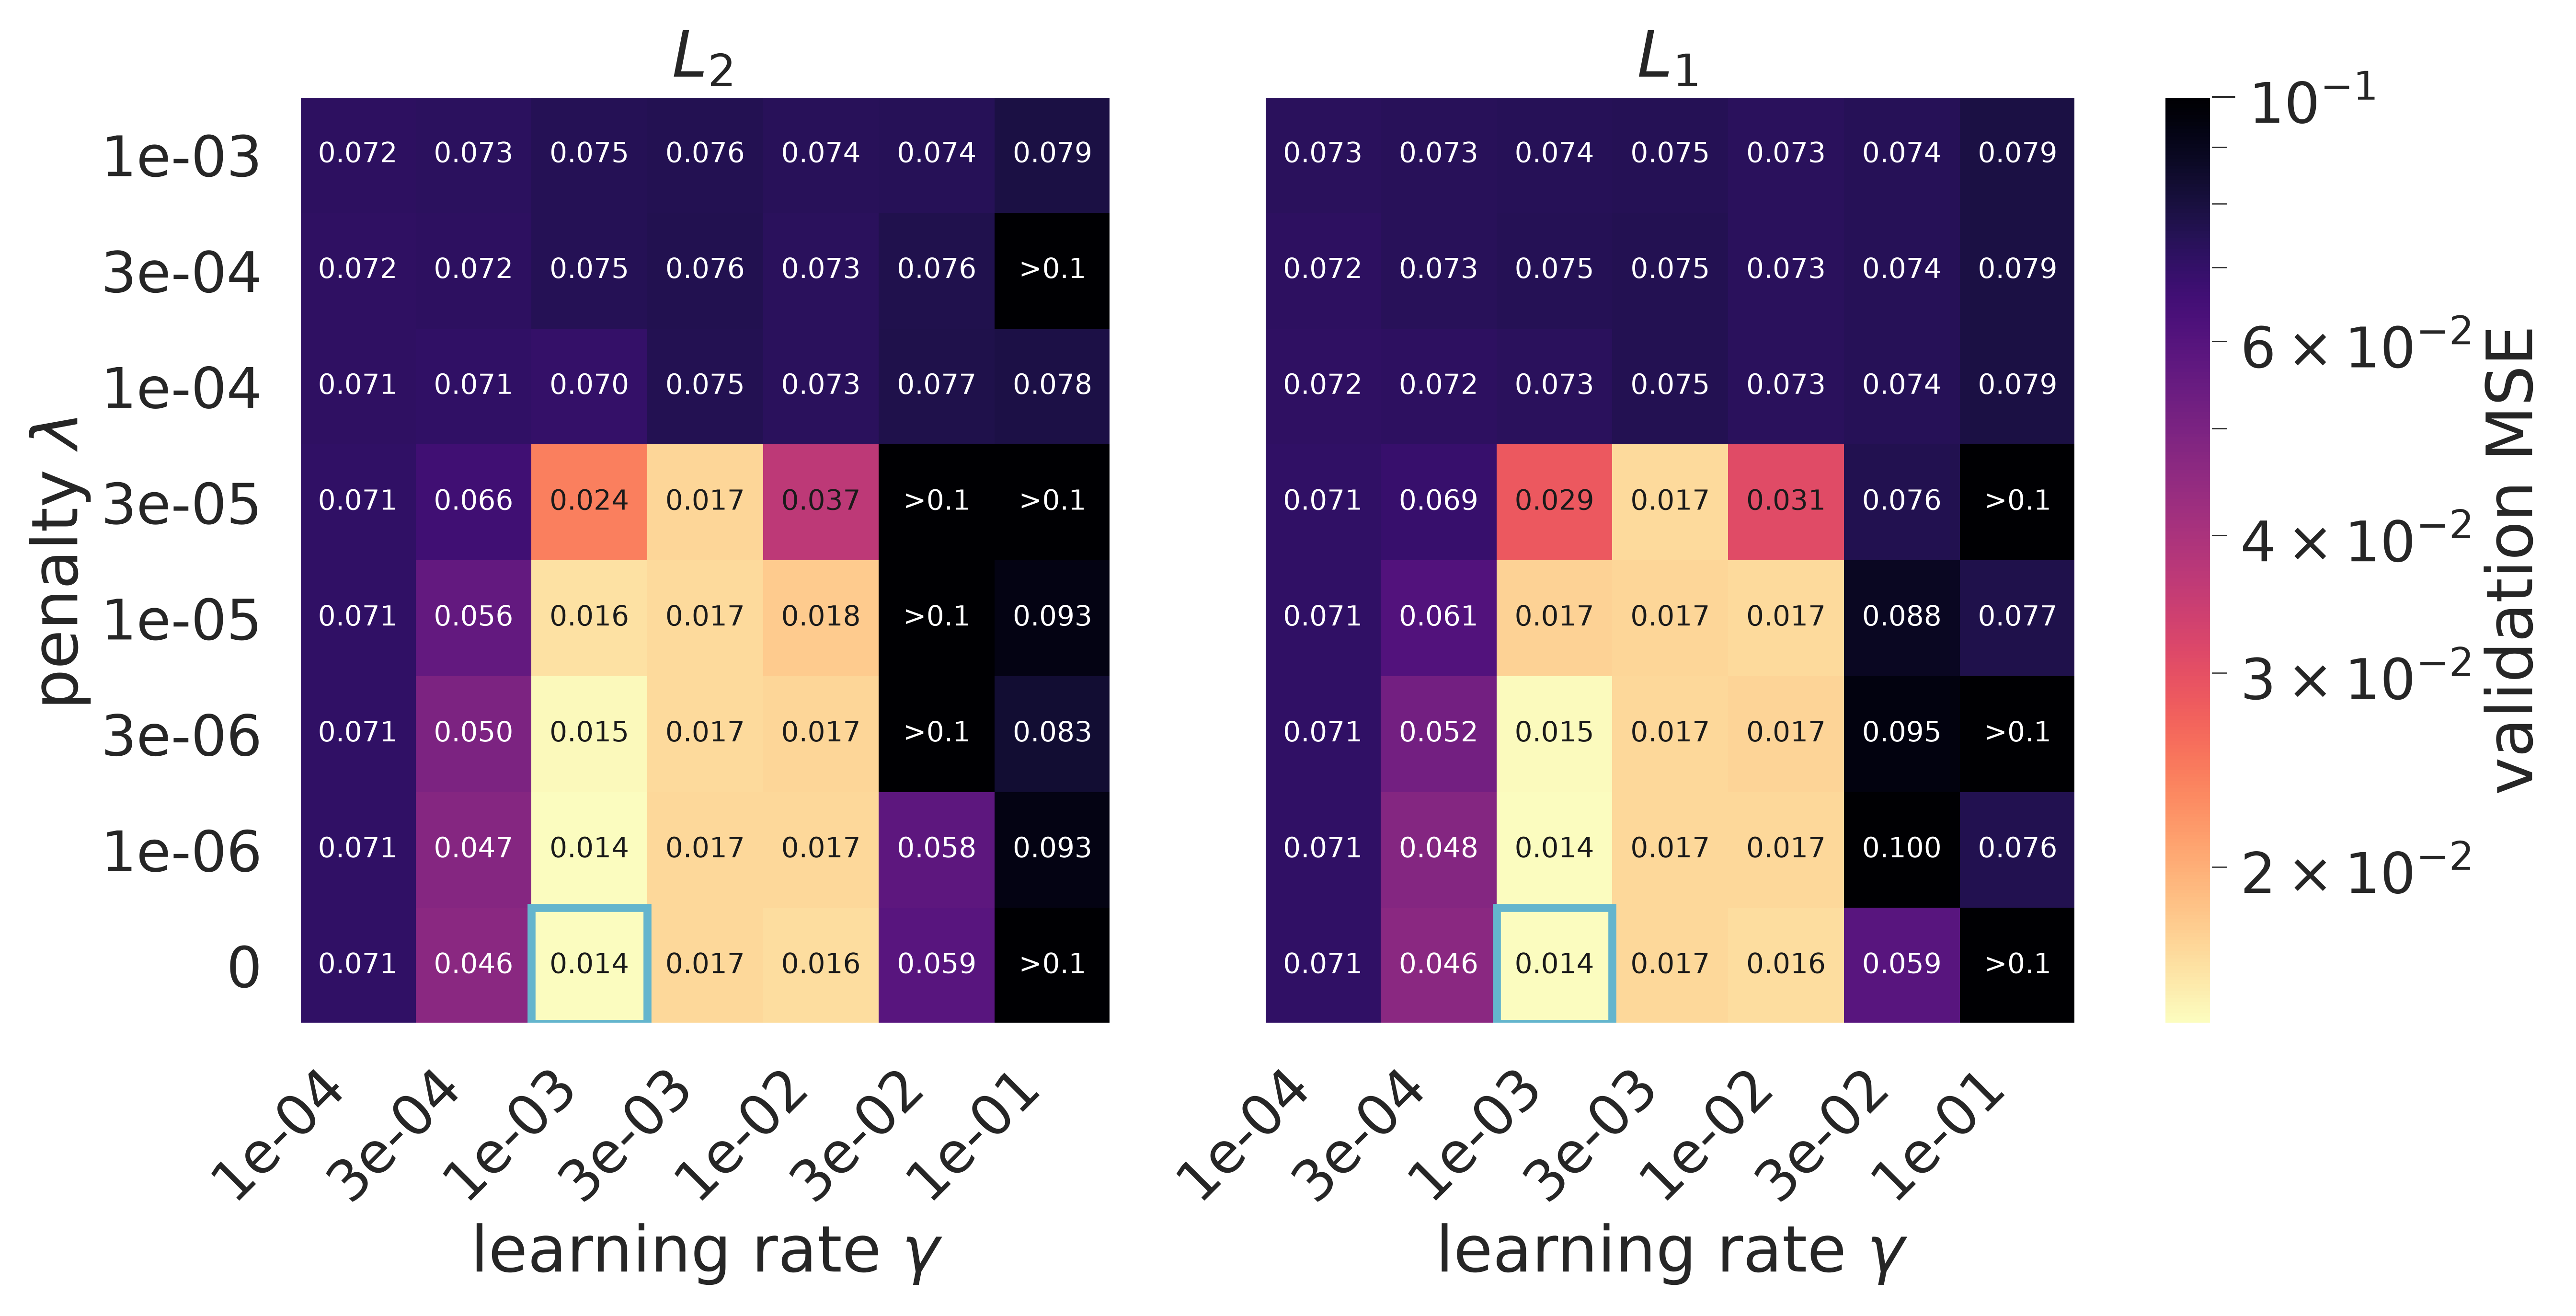

In [22]:
# ----- D3: Heat maps ----------------------------------------------------------
VMAX = 0.1      # above this, network is no better than predicting the mean
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6), sharey=True)
best, best_pen = {}, {}
for ax, norm in zip(axes, ["l2", "l1"]):
    M = res[norm].mean(axis=-1)     # average over seeds
    M = np.where(np.isfinite(M), M, np.nan)
    im = ax.imshow(M, origin="lower", cmap="magma_r",
                   norm=LogNorm(np.nanmin(M), VMAX))
    ax.grid(False)
    ax.set_xticks(range(len(GAMMAS_D)), [f"{g:.0e}" for g in GAMMAS_D], rotation=45, ha="right")
    ax.set_yticks(range(len(LAMBDAS)), [f"{l:.0e}" if l > 0 else "0" for l in LAMBDAS])
    ax.set_xlabel(r"learning rate $\gamma$")
    ax.set_title(rf"$L_{norm[1]}$")
    for (r, c), v in np.ndenumerate(M):
        if np.isfinite(v):
            txt = f"{v:.3f}" if v < VMAX else ">0.1"
            ax.text(c, r, txt, ha="center", va="center", fontsize=7,
                    color="w" if im.norm(v) > 0.5 else "k")
            
    # overall best cell and best cell with a real penalty, lambda > 0
    i, j = np.unravel_index(np.where(np.isfinite(M), M, np.inf).argmin(), M.shape)
    best[norm] = (LAMBDAS[i], GAMMAS_D[j], M[i, j])
    ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="c", lw=2))
    P = np.where(np.isfinite(M[1:]), M[1:], np.inf)
    i2, j2 = np.unravel_index(P.argmin(), P.shape)
    best_pen[norm] = (LAMBDAS[i2 + 1], GAMMAS_D[j2], P[i2, j2])
    print(f"{norm}: best lambda {best[norm][0]:.0e}, gamma {best[norm][1]:.0e}, "
          f"val MSE {best[norm][2]:.4f}")
    
axes[0].set_ylabel(r"penalty $\lambda$")
fig.colorbar(im, ax=axes, label="validation MSE")
fig.savefig(FIGURES_PATH / "D-lambda_gamma.pdf")

model            degree    lambda        test MSE
OLS (P1)             12   0.0e+00          0.0093
Ridge (P1)           14   4.0e-07          0.0105
Lasso (P1)           14   1.0e-08          0.0085
NN, no penalty        -   0.0e+00    0.0100 ± 0.0029
NN, L2                -   1.0e-06    0.0099 ± 0.0030
NN, L1                -   1.0e-06    0.0099 ± 0.0029


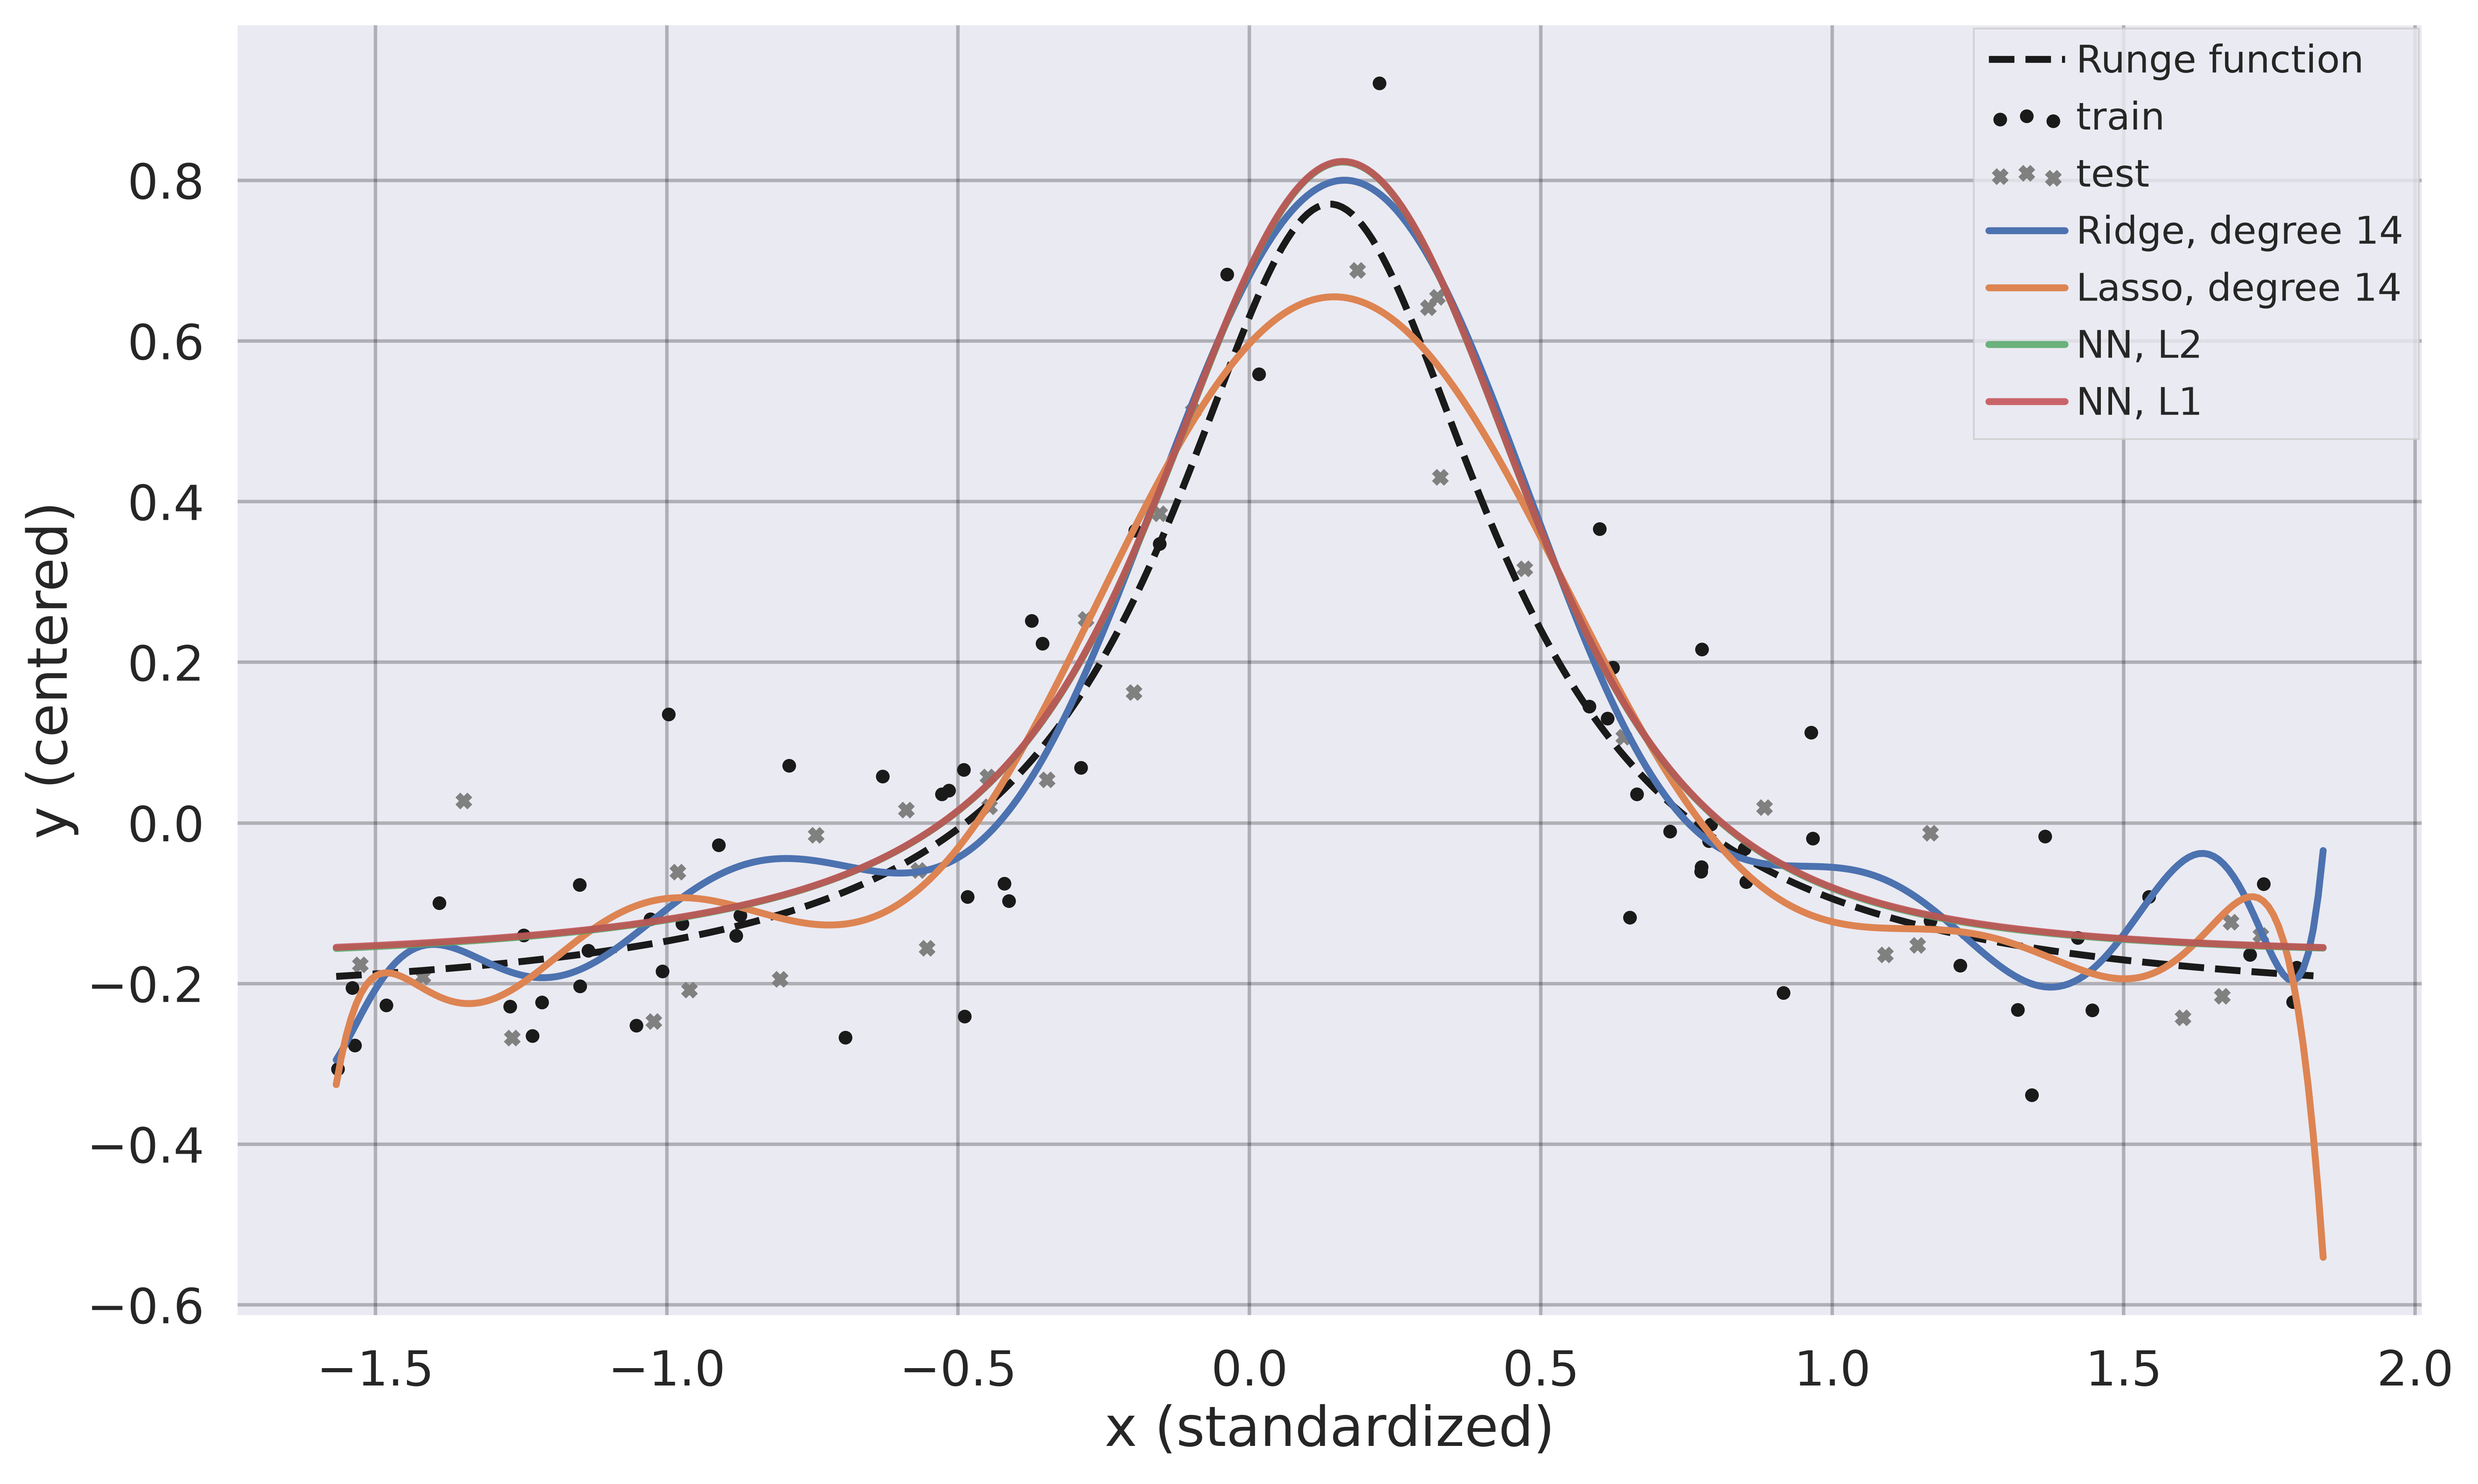

In [23]:
# ----- D4: Ridge and Lasso benchmarks (Project 1) -----------------------------
DEGREES = range(1, 21)
LAMS_P1 = np.logspace(-8, 0, 6)
K = 5
x_cv, y_cv = x_train.reshape(-1, 1), y_train.ravel()    # training data only

cv_path = RESULTS_PATH / "d_ridge_lasso_cv.npz"
if RERUN or not cv_path.exists():
    cv_ridge = np.zeros((len(DEGREES), len(LAMS_P1)))
    cv_lasso = np.zeros_like(cv_ridge)
    for j, lam in enumerate(LAMS_P1):
        cv_ridge[:, j] = u.k_fold_degrees(x_cv, y_cv, K, Ridge(alpha=lam), maxdegree=len(DEGREES))
        cv_lasso[:, j] = u.k_fold_degrees(x_cv, y_cv, K, Lasso(alpha=lam, max_iter=100_000), maxdegree=len(DEGREES))
    np.savez(cv_path, ridge=cv_ridge, lasso=cv_lasso)
else:
    saved = np.load(cv_path)
    cv_ridge, cv_lasso = saved["ridge"], saved["lasso"]
cv_ols = u.k_fold_degrees(x_cv, y_cv, K, LinearRegression(), maxdegree=len(DEGREES))

def poly_model(deg, model):
    return make_pipeline(PolynomialFeatures(degree=deg, include_bias=False), StandardScaler(), model)


# refit each winner on the whole training set, look at test set once
bench = {}
i = cv_ols.argmin()
fit = poly_model(DEGREES[i], LinearRegression()).fit(x_cv, y_cv)
bench["OLS"] = (DEGREES[i], 0.0, mse_score(y_test, fit.predict(x_test.reshape(-1, 1))), fit)
for name, cv, Model, kw in [("Ridge", cv_ridge, Ridge, {}), ("Lasso", cv_lasso, Lasso, {"max_iter": 100_000})]:
    i, j = np.unravel_index(cv.argmin(), cv.shape)
    fit = poly_model(DEGREES[i], Model(alpha=LAMS_P1[j], **kw)).fit(x_cv, y_cv)
    bench[name] = (DEGREES[i], LAMS_P1[j], mse_score(y_test, fit.predict(x_test.reshape(-1, 1))), fit)


# the network: retrain on full training set with chosen (lambda, gamma)
def final_nn(l1, l2, gamma, seeds=SEEDS_D):
    scores, nets = [], []
    for s in seeds:
        net = NeuralNetwork([1] + [WIDTH] * DEPTH + [1],
                            [ACT] * DEPTH + ["identity"],
                            "mse", lmbd1=l1, lmbd2=l2, seed=s)
        with np.errstate(all="ignore"):
            train(net, X_tr, Y_tr, method="rmsprop", gamma=gamma, epochs=EPOCHS_D,
                  batch_size=10, seed=s)
        scores.append(mse_score(Y_te, net.predict(X_te)))
        nets.append(net)
    return np.mean(scores), np.std(scores), nets[0]

(lam2, g2, _), (lam1, g1, _) = best_pen["l2"], best_pen["l1"]
nn = {"NN, no penalty": final_nn(0.0, 0.0, best["l2"][1]),
      "NN, L2": final_nn(0.0, lam2, g2),
      "NN, L1": final_nn(lam1, 0.0, g1)}
lams = {"NN, no penalty": 0.0, "NN, L2": lam2, "NN, L1": lam1}

print(f"{'model':<16}{'degree':>7}{'lambda':>10}{'test MSE':>16}")
for name, (deg, lam, te, _) in bench.items():
    print(f"{name + ' (P1)':<16}{deg:>7}{lam:>10.1e}{te:>16.4f}")
for name, (m, s, _) in nn.items():
    print(f"{name:<16}{'-':>7}{lams[name]:>10.1e}{m:>10.4f} ± {s:.4f}")
    

# fitted curves
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(xg_std, 1 / (1 + 25 * xg**2) - y_raw.mean(), "k--", label="Runge function")
ax.scatter(x_train, y_train, s=12, color="k", label="train")
ax.scatter(x_test, y_test, s=12, color="gray", marker="x", label="test")
for name in ("Ridge", "Lasso"):
    deg, lam, _, fit = bench[name]
    ax.plot(xg_std, fit.predict(xg_std.reshape(-1, 1)), label=f"{name}, degree {deg}")
for name in ("NN, L2", "NN, L1"):
    ax.plot(xg_std, nn[name][2].predict(to_column(xg_std)).ravel(), label=name, alpha=0.85)
ax.set_xlabel("x (standardized)")
ax.set_ylabel("y (centered)")
ax.legend(loc="upper right", fontsize=11)
fig.savefig(FIGURES_PATH / "D-NN_vs_Ridge_Lasso.pdf")

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part e)** Classification analysis

</div>

In [24]:
x_train, y_train, x_test, y_test = load_mnist(DATA_PATH)
x_fit, x_val, y_fit, y_val = train_val_split(x_train, y_train, val_size=0.25, seed=SEED, stratify=False)
Y_fit, Y_val = one_hot(y_fit), one_hot(y_val)   # train needs (n, 10)

print("Train: ", x_fit.shape, y_fit.shape)
print("Val:   ", x_val.shape, y_val.shape)
print("Test:  ", x_test.shape, y_test.shape)

Train:  (45000, 784) (45000,)
Val:    (15000, 784) (15000,)
Test:   (10000, 784) (10000,)


In [25]:
logreg_path = RESULTS_PATH / "e_log_reg.npz"
if RERUN or not logreg_path.exists():
    # initialize model
    logreg_model = LogisticRegression(solver="saga", max_iter=1000, random_state=42)
    logreg_model.fit(x_train, y_train)
    np.savez(logreg_path, model=logreg_model)
else:
    logreg_model = np.load(logreg_path, allow_pickle=True)["model"].item()
    
# make predictions on the test set, and calculate accuracy
y_pred = logreg_model.predict(x_test)
logreg_acc = accuracy(y_test, y_pred)
print(f"Model Accuracy: {logreg_acc:.4f}")

Model Accuracy: 0.9257


In [26]:
def run_one_mnist(act, hidden, lam, gamma, epochs, batch_size, seed):
    '''
    Args
    ---
    act : activation function, i.e., "relu"
    hidden : hidden layers, i.e., (128, 64)
    lam : (lambda1, lambda2)
    '''
    l1, l2 = lam
    
    # Set up net with 10 output layers
    n_in = 784
    n_out = 10
    sizes = [n_in, *hidden, n_out]
    acts = [act] * (len(sizes) - 2) + ["softmax"]
    net = NeuralNetwork(sizes, acts, "cross_entropy", lmbd1=l1, lmbd2=l2, seed=seed)
    
    # Train on mnist fit set
    hist = train(net, x_fit, Y_fit, method="adam", gamma=gamma,
                 epochs=epochs, batch_size=batch_size,
                 X_val=x_val, Y_val=Y_val, seed=seed)
    
    # Calculate accuracy on validation set
    y_pred = np.argmax(net.predict(x_val), axis=1)
    acc = accuracy(y_val, y_pred)
    
    run = {"train_cost": hist["train_cost"][-1],
           "val_cost": hist["val_cost"][-1],
           "accuracy": acc}
    return run


mnist_path = RESULTS_PATH / "e-mnist-runone.npz"
if RERUN or not mnist_path.exists():
       ...
else:
       ...
       
test_run = run_one_mnist("relu", (64,), (1e-5, 0.0), 1e-3, 2, 128, SEED)
print(test_run["accuracy"])

0.9419333333333333


<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part f)** Various algorithms

</div>